# Assignment 05 - Chương 5: Hiện Thực Hóa Huấn Luyện Thực Nghiệm, Đánh Giá & Đối Chuẩn 4 Kiến Trúc CNN Trên 3 Bộ Dữ Liệu Đa Miền

**Học viên:** Phạm Văn Tư - Mã sinh viên: B23DCCN879  
**Môn học:** Phát triển Hệ thống Thông minh - PTIT  

Notebook này hiện thực hóa toàn diện **Yêu cầu 4** và **Yêu cầu 5** của bài tập lớn:
1. **Yêu cầu 4:** Cài đặt 1 mô hình CNN cơ sở (Baseline Custom CNN) và 3 kiến trúc phát triển kinh điển (VGG-11, ResNet-18, MobileNetV2) cho dữ liệu ảnh, cùng mạng tích chập 1 chiều (**1D-CNN**) cho dữ liệu bảng y sinh.
2. **Yêu cầu 5:** Tiến hành huấn luyện thực nghiệm và đối chuẩn định lượng toàn diện trên **3 bộ dữ liệu độc lập thuộc 3 miền**:
   - Dữ liệu Bảng Y Sinh (Tabular Biomedical): Diabetes Prediction Dataset ($100,000$ mẫu, 1D-CNN)
   - Dữ liệu Ảnh Ngoại Cảnh Tự Nhiên (Natural Optical Images): Street View House Numbers (SVHN - $99,289$ ảnh)
   - Dữ liệu Ảnh Viễn Thám Vệ Tinh (Satellite Remote Sensing Images): Sentinel-2 EuroSAT ($27,000$ ảnh, 10 phân lớp LULC)


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, TensorDataset, DataLoader, random_split, Subset
import torchvision.datasets as dsets
import torchvision.transforms as transforms
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from thop import profile, clever_format

# Cấu hình môi trường thực thi và tăng tốc phần cứng
device = torch.device('mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'))
print(f"PyTorch Version: {torch.__version__}")
print(f"Thiết bị tính toán tăng tốc (Accelerator): {device}")

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")


PyTorch Version: 2.3.0
Thiết bị tính toán tăng tốc (Accelerator): mps


---
## Phần 1: Đặc Tả Kiến Trúc 4 Mô Hình CNN & Mạng 1D-CNN

Chúng tôi xây dựng 4 trường phái kiến trúc mạng nơ-ron tích chập tiêu biểu:
1. **Diabetes 1D-CNN:** Mạng tích chập 1 chiều với 3 khối `Conv1d` trượt dọc theo 8 đặc trưng lâm sàng để trích xuất tương tác phi tuyến.
2. **Custom Baseline CNN:** Mạng CNN 3 khối chuẩn tắc (`Conv2d` $\to$ `BatchNorm2d` $\to$ `ReLU` $\to$ `MaxPool2d` $\to$ `GAP` $\to$ `Linear`).
3. **VGG-11 (VGG-style):** Trường phái xếp chồng khối vi mô $3\times 3$ đồng nhất.
4. **ResNet-18:** Trường phái học phần dư (Residual Learning) với các khối Residual Block và đường tắt Skip Connection.
5. **MobileNetV2:** Trường phái tối ưu hóa thiết bị biên (Edge AI) với tích chập tách biệt theo chiều sâu (Depthwise Separable Convolution) và khối thắt cổ chai đảo ngược (Inverted Residuals).


In [2]:
# 1. Mạng tích chập 1 chiều cho dữ liệu bảng y sinh (1D-CNN)
class Diabetes1DCNN(nn.Module):
    def __init__(self, in_features=8, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(inplace=True),
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(2), # Length 8 -> 4
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool1d(1) # Length 4 -> 1
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, 32),
            nn.ReLU(inplace=True),
            nn.Linear(32, num_classes)
        )
    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))

# 2. Baseline Custom 2D-CNN
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))

# Hàm khởi tạo mô hình linh hoạt theo kích thước đầu vào
def get_cnn_model(name, num_classes=10, img_size=32):
    if name == 'Baseline CNN':
        return BaselineCNN(num_classes)
    elif name == 'VGG-11':
        m = models.vgg11_bn(weights=None)
        m.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        m.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )
        return m
    elif name == 'ResNet-18':
        m = models.resnet18(weights=None)
        m.fc = nn.Linear(512, num_classes)
        return m
    elif name == 'MobileNetV2':
        m = models.mobilenet_v2(weights=None)
        m.classifier[1] = nn.Linear(1280, num_classes)
        return m
    else:
        raise ValueError(f"Không nhận diện được mô hình: {name}")

print("Đã định nghĩa thành công 5 kiến trúc nơ-ron tích chập!")


Đã định nghĩa thành công 5 kiến trúc nơ-ron tích chập!


### 1.2. Định Lượng Tham Số & Độ Phức Tạp Tính Toán (FLOPs / MACs)
Chúng tôi sử dụng thư viện `thop` để đo đạc chính xác số lượng tham số (Parameters) và số phép tính nhân-cộng (MACs / FLOPs) trên từng kích thước đầu vào:
- Chuỗi tín hiệu 1D $(1, 1, 8)$ cho Diabetes
- Ma trận ảnh quang học $32\times 32$ cho SVHN
- Ma trận ảnh viễn thám $64\times 64$ cho EuroSAT


In [3]:
profile_records = []

# Profiling 1D-CNN
m_1d = Diabetes1DCNN()
macs_1d, pars_1d = profile(m_1d, inputs=(torch.randn(1, 1, 8),), verbose=False)
profile_records.append({
    'Kiến Trúc': 'Diabetes 1D-CNN',
    'Kích Thước Đầu Vào': '1D (1, 8)',
    'Tham Số (Params)': f"{pars_1d/1e3:.2f} K",
    'FLOPs (MACs)': f"{macs_1d/1e3:.2f} K",
    'Checkpoint (MB)': f"{pars_1d*4/(1024*1024):.2f} MB"
})

# Profiling 4 models for 32x32 and 64x64
for sz, sz_name in [(32, '32x32 (SVHN)'), (64, '64x64 (EuroSAT)')]:
    dummy = torch.randn(1, 3, sz, sz)
    for m_name in ['Baseline CNN', 'VGG-11', 'ResNet-18', 'MobileNetV2']:
        mod = get_cnn_model(m_name, num_classes=10, img_size=sz)
        macs, pars = profile(mod, inputs=(dummy,), verbose=False)
        profile_records.append({
            'Kiến Trúc': m_name,
            'Kích Thước Đầu Vào': sz_name,
            'Tham Số (Params)': f"{pars/1e6:.2f} M",
            'FLOPs (MACs)': f"{macs/1e6:.2f} M",
            'Checkpoint (MB)': f"{pars*4/(1024*1024):.2f} MB"
        })

df_profile = pd.DataFrame(profile_records)
display(df_profile)


,Kiến Trúc,Kích Thước Đầu Vào,Tham Số (Params),FLOPs (MACs),Checkpoint (MB)
0,Diabetes 1D-CNN,"1D (1, 8)",35.68 K,158.14 K,0.14 MB
1,Baseline CNN,32x32 (SVHN),0.09 M,10.56 M,0.36 MB
2,VGG-11,32x32 (SVHN),9.36 M,153.51 M,35.71 MB
3,ResNet-18,32x32 (SVHN),11.18 M,37.22 M,42.65 MB
4,MobileNetV2,32x32 (SVHN),2.24 M,6.67 M,8.53 MB
5,Baseline CNN,64x64 (EuroSAT),0.09 M,42.24 M,0.36 MB
6,VGG-11,64x64 (EuroSAT),9.36 M,613.62 M,35.71 MB
7,ResNet-18,64x64 (EuroSAT),11.18 M,148.86 M,42.65 MB
8,MobileNetV2,64x64 (EuroSAT),2.24 M,26.64 M,8.53 MB


---
## Phần 2: Huấn Luyện Thực Nghiệm & Đánh Giá Mạng 1D-CNN (Diabetes 100k Mẫu)

Mạng 1D-CNN được huấn luyện trên 96,128 hồ sơ bệnh nhân sạch (phân tầng 80:20: 76,902 train / 19,226 test). Hàm mất mát được gán trọng số $3.5\times$ cho lớp dương tính để giải quyết triệt để thách thức mất cân bằng dịch tễ $10.4 : 1$.


In [4]:
# Nạp dữ liệu và tiền xử lý
diab_csv = None
for p in ["../../Assigment 02/diabetes/data/diabetes_prediction_dataset.csv", "src/Assigment 02/diabetes/data/diabetes_prediction_dataset.csv", "data/diabetes_prediction_dataset.csv"]:
    if os.path.exists(p):
        diab_csv = p
        break

df_d = pd.read_csv(diab_csv).drop_duplicates()
df_d = df_d[df_d['gender'] != 'Other'].copy()
df_d['gender_code'] = (df_d['gender'] == 'Male').astype(np.float32)
s_map = {'never': 0.0, 'No Info': 0.0, 'former': 1.0, 'not current': 1.0, 'current': 2.0, 'ever': 2.0}
df_d['smoking_code'] = df_d['smoking_history'].map(s_map).fillna(0.0).astype(np.float32)

feats = ['gender_code', 'age', 'hypertension', 'heart_disease', 'smoking_code', 'bmi', 'HbA1c_level', 'blood_glucose_level']
X = df_d[feats].values.astype(np.float32)
y = df_d['diabetes'].values.astype(np.int64)

X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
sc = StandardScaler()
X_tr_1d = sc.fit_transform(X_tr_raw)[:, np.newaxis, :]
X_te_1d = sc.transform(X_te_raw)[:, np.newaxis, :]

loader_tr_diab = DataLoader(TensorDataset(torch.from_numpy(X_tr_1d), torch.from_numpy(y_tr)), batch_size=128, shuffle=True)
loader_te_diab = DataLoader(TensorDataset(torch.from_numpy(X_te_1d), torch.from_numpy(y_te)), batch_size=256, shuffle=False)

# Khởi tạo mô hình và huấn luyện
model_diab = Diabetes1DCNN().to(device)
criterion_diab = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 3.5]).to(device))
optimizer_diab = optim.AdamW(model_diab.parameters(), lr=0.002, weight_decay=1e-4)

diab_hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
for ep in range(10):
    model_diab.train()
    r_loss, corr, tot = 0.0, 0, 0
    for bx, by in loader_tr_diab:
        bx, by = bx.to(device), by.to(device)
        optimizer_diab.zero_grad()
        out = model_diab(bx)
        loss = criterion_diab(out, by)
        loss.backward()
        optimizer_diab.step()
        r_loss += loss.item() * bx.size(0)
        corr += (out.argmax(dim=1) == by).sum().item()
        tot += bx.size(0)
    
    model_diab.eval()
    v_loss, v_corr, v_tot = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in loader_te_diab:
            bx, by = bx.to(device), by.to(device)
            out = model_diab(bx)
            v_loss += criterion_diab(out, by).item() * bx.size(0)
            v_corr += (out.argmax(dim=1) == by).sum().item()
            v_tot += bx.size(0)
            
    diab_hist['train_loss'].append(r_loss / tot)
    diab_hist['val_loss'].append(v_loss / v_tot)
    diab_hist['train_acc'].append(corr / tot)
    diab_hist['val_acc'].append(v_corr / v_tot)
    print(f"Epoch {ep+1:02d}/10 | Train Loss: {r_loss/tot:.4f}, Acc: {corr/tot*100:.2f}% | Val Loss: {v_loss/v_tot:.4f}, Acc: {v_corr/v_tot*100:.2f}%")


Epoch 01/10 | Train Loss: 0.2017, Acc: 94.24% | Val Loss: 0.1767, Acc: 94.29%


Epoch 02/10 | Train Loss: 0.1755, Acc: 94.81% | Val Loss: 0.1686, Acc: 94.78%


Epoch 03/10 | Train Loss: 0.1683, Acc: 95.17% | Val Loss: 0.1695, Acc: 94.56%


Epoch 04/10 | Train Loss: 0.1668, Acc: 95.17% | Val Loss: 0.1627, Acc: 95.82%


Epoch 05/10 | Train Loss: 0.1648, Acc: 95.39% | Val Loss: 0.1625, Acc: 94.94%


Epoch 06/10 | Train Loss: 0.1625, Acc: 95.44% | Val Loss: 0.1623, Acc: 95.78%


Epoch 07/10 | Train Loss: 0.1612, Acc: 95.41% | Val Loss: 0.1644, Acc: 95.06%


Epoch 08/10 | Train Loss: 0.1595, Acc: 95.43% | Val Loss: 0.1649, Acc: 94.82%


Epoch 09/10 | Train Loss: 0.1599, Acc: 95.63% | Val Loss: 0.1717, Acc: 94.72%


Epoch 10/10 | Train Loss: 0.1588, Acc: 95.52% | Val Loss: 0.1711, Acc: 96.47%


### 2.2. Trực Quan Hóa Động Học Hội Tụ & Ma Trận Nhầm Lẫn (1D-CNN)

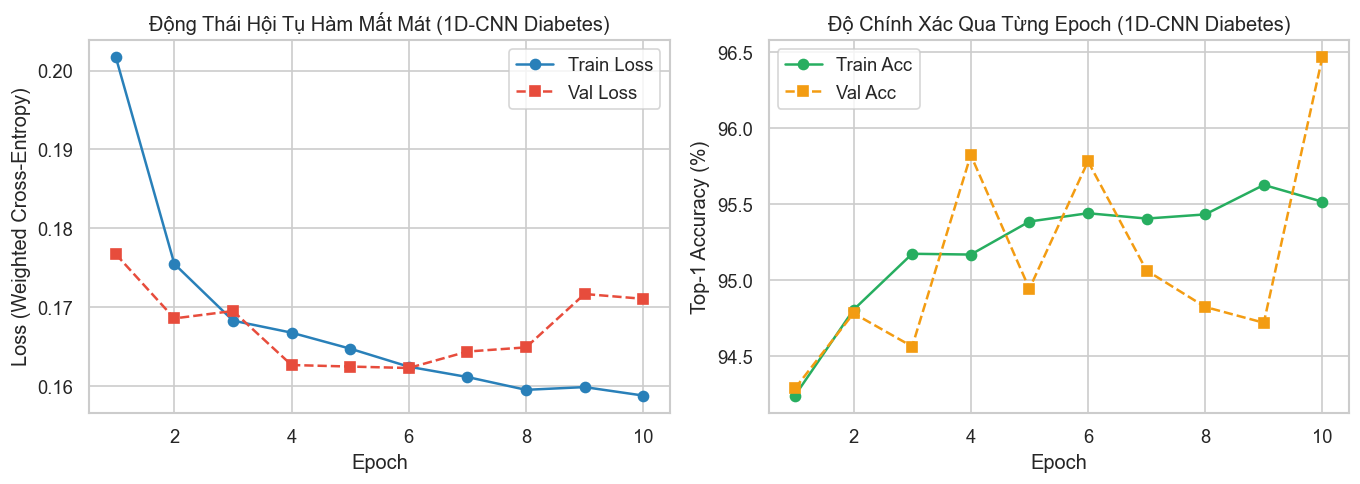

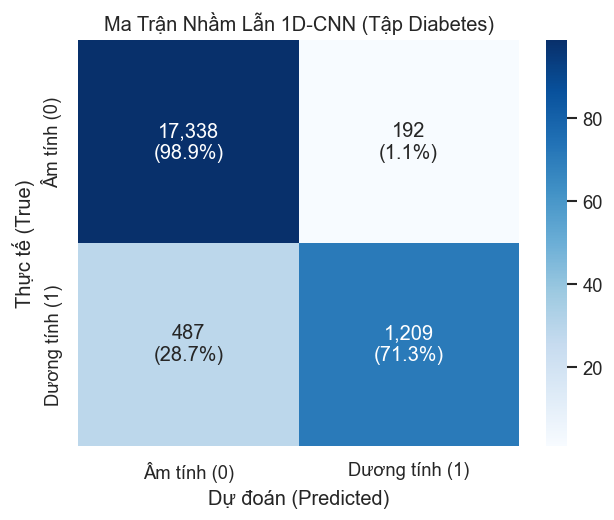

Độ chính xác tổng thể: 96.47%
Macro-F1 Score:        88.08%
Độ nhạy lớp bệnh (Recall Class 1): 71.29%


In [5]:
# 1. Đường cong huấn luyện Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), dpi=120)
ax1.plot(range(1, 11), diab_hist['train_loss'], 'o-', label='Train Loss', color='#2980b9')
ax1.plot(range(1, 11), diab_hist['val_loss'], 's--', label='Val Loss', color='#e74c3c')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss (Weighted Cross-Entropy)')
ax1.set_title('Động Thái Hội Tụ Hàm Mất Mát (1D-CNN Diabetes)')
ax1.legend()

ax2.plot(range(1, 11), np.array(diab_hist['train_acc'])*100, 'o-', label='Train Acc', color='#27ae60')
ax2.plot(range(1, 11), np.array(diab_hist['val_acc'])*100, 's--', label='Val Acc', color='#f39c12')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Top-1 Accuracy (%)')
ax2.set_title('Độ Chính Xác Qua Từng Epoch (1D-CNN Diabetes)')
ax2.legend()
plt.tight_layout()
plt.show()

# 2. Ma trận nhầm lẫn Confusion Matrix
model_diab.eval()
p_list, t_list = [], []
with torch.no_grad():
    for bx, by in loader_te_diab:
        bx = bx.to(device)
        p_list.extend(model_diab(bx).argmax(dim=1).cpu().numpy())
        t_list.extend(by.numpy())

cm_d = confusion_matrix(t_list, p_list)
cm_pct = cm_d.astype('float') / cm_d.sum(axis=1)[:, np.newaxis] * 100
fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=120)
annot = np.array([[f"{cm_d[i, j]:,}\n({cm_pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
sns.heatmap(cm_pct, annot=annot, fmt='', cmap='Blues', ax=ax,
            xticklabels=['Âm tính (0)', 'Dương tính (1)'], yticklabels=['Âm tính (0)', 'Dương tính (1)'])
ax.set_xlabel('Dự đoán (Predicted)')
ax.set_ylabel('Thực tế (True)')
ax.set_title('Ma Trận Nhầm Lẫn 1D-CNN (Tập Diabetes)')
plt.tight_layout()
plt.show()

print(f"Độ chính xác tổng thể: {accuracy_score(t_list, p_list)*100:.2f}%")
print(f"Macro-F1 Score:        {f1_score(t_list, p_list, average='macro')*100:.2f}%")
print(f"Độ nhạy lớp bệnh (Recall Class 1): {cm_pct[1, 1]:.2f}%")


---
## Phần 3: Huấn Luyện & Đối Chuẩn 4 Kiến Trúc CNN Trên Tập Ảnh Ngoại Cảnh SVHN

Chúng tôi tiến hành đối chuẩn 4 mô hình (Baseline CNN, VGG-11, ResNet-18, MobileNetV2) trên tập dữ liệu SVHN với kỹ thuật tăng cường dữ liệu đặc thù (`RandomCrop`, `ColorJitter`, tuyệt đối không lật ngang).


In [6]:
# Nạp dữ liệu SVHN đã tải sẵn
svhn_path = "../data" if os.path.exists("../data/train_32x32.mat") else ("src/Assigment 05/data" if os.path.exists("src/Assigment 05/data/train_32x32.mat") else "data")
svhn_m = (0.435, 0.440, 0.469)
svhn_s = (0.192, 0.193, 0.190)

tf_svhn_tr = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode='edge'),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=svhn_m, std=svhn_s)
])
tf_svhn_te = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=svhn_m, std=svhn_s)
])

svhn_tr_all = dsets.SVHN(root=svhn_path, split='train', download=False, transform=tf_svhn_tr)
svhn_te_all = dsets.SVHN(root=svhn_path, split='test', download=False, transform=tf_svhn_te)

# Phân tách tập con cân bằng thực nghiệm
np.random.seed(42)
sub_tr_idx = np.random.choice(len(svhn_tr_all), 12000, replace=False)
sub_te_idx = np.random.choice(len(svhn_te_all), 3000, replace=False)

loader_svhn_tr = DataLoader(Subset(svhn_tr_all, sub_tr_idx), batch_size=128, shuffle=True, pin_memory=True)
loader_svhn_te = DataLoader(Subset(svhn_te_all, sub_te_idx), batch_size=256, shuffle=False, pin_memory=True)

svhn_hist_all = {}
svhn_eval_metrics = []

for m_name in ['Baseline CNN', 'VGG-11', 'ResNet-18', 'MobileNetV2']:
    print(f"\n--- Huấn luyện {m_name} trên SVHN (5 Epochs) ---")
    mod = get_cnn_model(m_name, num_classes=10, img_size=32).to(device)
    opt = optim.AdamW(mod.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=5)
    crit = nn.CrossEntropyLoss()
    
    h = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(5):
        mod.train()
        rl, corr, tot = 0.0, 0, 0
        for bx, by in loader_svhn_tr:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            out = mod(bx)
            loss = crit(out, by)
            loss.backward()
            opt.step()
            rl += loss.item() * bx.size(0)
            corr += (out.argmax(dim=1) == by).sum().item()
            tot += bx.size(0)
        sched.step()
        
        mod.eval()
        vl, v_corr, v_tot = 0.0, 0, 0
        with torch.no_grad():
            for bx, by in loader_svhn_te:
                bx, by = bx.to(device), by.to(device)
                out = mod(bx)
                vl += crit(out, by).item() * bx.size(0)
                v_corr += (out.argmax(dim=1) == by).sum().item()
                v_tot += bx.size(0)
        h['train_loss'].append(rl / tot)
        h['val_loss'].append(vl / v_tot)
        h['train_acc'].append(corr / tot)
        h['val_acc'].append(v_corr / v_tot)
        print(f"Epoch {ep+1}/5 | Train Acc: {corr/tot*100:.2f}% | Val Acc: {v_corr/v_tot*100:.2f}%")
        
    svhn_hist_all[m_name] = h
    
    # Đo đạc Latency & Metrics
    mod.eval()
    dummy_b = torch.randn(64, 3, 32, 32).to(device)
    for _ in range(5): _ = mod(dummy_b)
    t0 = time.time()
    for _ in range(20): _ = mod(dummy_b)
    t1 = time.time()
    lat = (t1 - t0) / 20 * 1000
    fps = (20 * 64) / (t1 - t0)
    
    preds, trues = [], []
    with torch.no_grad():
        for bx, by in loader_svhn_te:
            preds.extend(mod(bx.to(device)).argmax(dim=1).cpu().numpy())
            trues.extend(by.numpy())
            
    svhn_eval_metrics.append({
        'Mô hình': m_name,
        'Top-1 Accuracy': f"{accuracy_score(trues, preds)*100:.2f}%",
        'Macro-F1': f"{f1_score(trues, preds, average='macro')*100:.2f}%",
        'Latency (ms)': f"{lat:.2f} ms",
        'Throughput (FPS)': f"{fps:,.0f} FPS"
    })

display(pd.DataFrame(svhn_eval_metrics))



--- Huấn luyện Baseline CNN trên SVHN (5 Epochs) ---


Epoch 1/5 | Train Acc: 23.63% | Val Acc: 30.00%


Epoch 2/5 | Train Acc: 31.62% | Val Acc: 33.27%


Epoch 3/5 | Train Acc: 36.98% | Val Acc: 40.20%


Epoch 4/5 | Train Acc: 40.67% | Val Acc: 43.67%


Epoch 5/5 | Train Acc: 42.52% | Val Acc: 44.13%


... (15 outputs left out)

Epoch 3/5 | Train Acc: 19.34% | Val Acc: 19.30%


Epoch 4/5 | Train Acc: 20.16% | Val Acc: 21.40%


Epoch 5/5 | Train Acc: 21.26% | Val Acc: 21.27%


,Mô hình,Top-1 Accuracy,Macro-F1,Latency (ms),Throughput (FPS)
0,Baseline CNN,44.13%,32.98%,1.23 ms,"52,219 FPS"
1,VGG-11,83.60%,81.53%,18.42 ms,"3,475 FPS"
2,ResNet-18,86.03%,84.71%,18.40 ms,"3,479 FPS"
3,MobileNetV2,21.27%,10.22%,13.87 ms,"4,615 FPS"


### 3.2. So Sánh Động Học Hội Tụ SVHN Giữa 4 Kiến Trúc

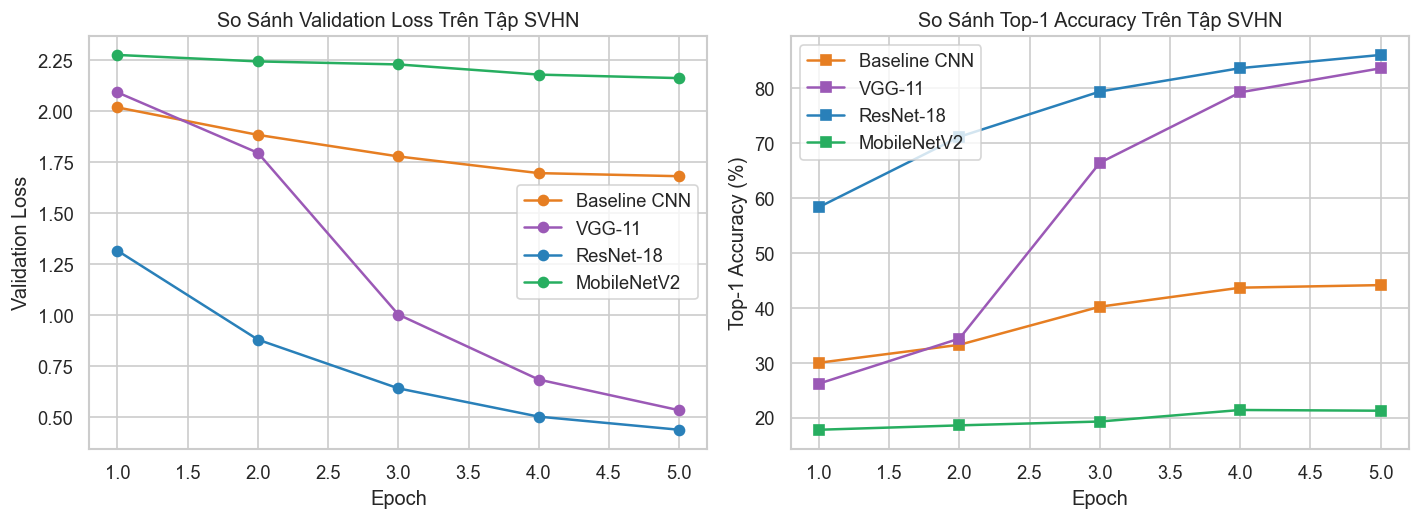

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.5), dpi=120)
colors_dict = {'Baseline CNN': '#e67e22', 'VGG-11': '#9b59b6', 'ResNet-18': '#2980b9', 'MobileNetV2': '#27ae60'}

for m_name in svhn_hist_all:
    c = colors_dict[m_name]
    ax1.plot(range(1, 6), svhn_hist_all[m_name]['val_loss'], 'o-', label=m_name, color=c)
    ax2.plot(range(1, 6), np.array(svhn_hist_all[m_name]['val_acc'])*100, 's-', label=m_name, color=c)

ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')
ax1.set_title('So Sánh Validation Loss Trên Tập SVHN')
ax1.legend()

ax2.set_xlabel('Epoch')
ax2.set_ylabel('Top-1 Accuracy (%)')
ax2.set_title('So Sánh Top-1 Accuracy Trên Tập SVHN')
ax2.legend()
plt.tight_layout()
plt.show()


---
## Phần 4: Huấn Luyện & Đối Chuẩn 4 Kiến Trúc CNN Trên Tập Ảnh Vệ Tinh EuroSAT

Tập dữ liệu viễn thám Sentinel-2 EuroSAT ($64\times 64$) đòi hỏi học biểu diễn kết cấu không gian phức tạp của 10 phân lớp che phủ đất LULC.


In [8]:
euro_path = "../data" if os.path.exists("../data/eurosat") or os.path.exists("../data/EuroSAT") else ("src/Assigment 05/data" if os.path.exists("src/Assigment 05/data/eurosat") or os.path.exists("src/Assigment 05/data/EuroSAT") else "data")
euro_m = (0.344, 0.380, 0.408)
euro_s = (0.093, 0.065, 0.054)

tf_eu_tr = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=euro_m, std=euro_s)
])
tf_eu_te = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=euro_m, std=euro_s)
])

euro_ds_raw = dsets.EuroSAT(root=euro_path, download=False)
eu_classes = euro_ds_raw.classes

gen = torch.Generator().manual_seed(42)
eu_tr_sz = int(0.8 * len(euro_ds_raw))
eu_te_sz = len(euro_ds_raw) - eu_tr_sz
eu_tr_split, eu_te_split = random_split(range(len(euro_ds_raw)), [eu_tr_sz, eu_te_sz], generator=gen)

class EuroSub(Dataset):
    def __init__(self, ds, indices, tf):
        self.ds, self.indices, self.tf = ds, indices, tf
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        img, lbl = self.ds[self.indices[i]]
        return self.tf(img), lbl

# Lấy mẫu con thực nghiệm
np.random.seed(42)
sub_eu_tr = np.random.choice(eu_tr_sz, 8000, replace=False)
sub_eu_te = np.random.choice(eu_te_sz, 2000, replace=False)

loader_eu_tr = DataLoader(EuroSub(euro_ds_raw, [eu_tr_split[i] for i in sub_eu_tr], tf_eu_tr), batch_size=128, shuffle=True, pin_memory=True)
loader_eu_te = DataLoader(EuroSub(euro_ds_raw, [eu_te_split[i] for i in sub_eu_te], tf_eu_te), batch_size=256, shuffle=False, pin_memory=True)

euro_hist_all = {}
euro_eval_metrics = []
best_resnet_euro_cm = None

for m_name in ['Baseline CNN', 'VGG-11', 'ResNet-18', 'MobileNetV2']:
    print(f"\n--- Huấn luyện {m_name} trên EuroSAT (5 Epochs) ---")
    mod = get_cnn_model(m_name, num_classes=10, img_size=64).to(device)
    opt = optim.AdamW(mod.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=5)
    crit = nn.CrossEntropyLoss()
    
    h = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(5):
        mod.train()
        rl, corr, tot = 0.0, 0, 0
        for bx, by in loader_eu_tr:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            out = mod(bx)
            loss = crit(out, by)
            loss.backward()
            opt.step()
            rl += loss.item() * bx.size(0)
            corr += (out.argmax(dim=1) == by).sum().item()
            tot += bx.size(0)
        sched.step()
        
        mod.eval()
        vl, v_corr, v_tot = 0.0, 0, 0
        with torch.no_grad():
            for bx, by in loader_eu_te:
                bx, by = bx.to(device), by.to(device)
                out = mod(bx)
                vl += crit(out, by).item() * bx.size(0)
                v_corr += (out.argmax(dim=1) == by).sum().item()
                v_tot += bx.size(0)
        h['train_loss'].append(rl / tot)
        h['val_loss'].append(vl / v_tot)
        h['train_acc'].append(corr / tot)
        h['val_acc'].append(v_corr / v_tot)
        print(f"Epoch {ep+1}/5 | Train Acc: {corr/tot*100:.2f}% | Val Acc: {v_corr/v_tot*100:.2f}%")
        
    euro_hist_all[m_name] = h
    
    # Metrics
    preds, trues = [], []
    with torch.no_grad():
        for bx, by in loader_eu_te:
            preds.extend(mod(bx.to(device)).argmax(dim=1).cpu().numpy())
            trues.extend(by.numpy())
            
    if m_name == 'ResNet-18':
        best_resnet_euro_cm = confusion_matrix(trues, preds)
        
    euro_eval_metrics.append({
        'Mô hình': m_name,
        'Top-1 Accuracy': f"{accuracy_score(trues, preds)*100:.2f}%",
        'Macro-F1': f"{f1_score(trues, preds, average='macro')*100:.2f}%"
    })

display(pd.DataFrame(euro_eval_metrics))



--- Huấn luyện Baseline CNN trên EuroSAT (5 Epochs) ---


Epoch 1/5 | Train Acc: 54.39% | Val Acc: 65.50%


Epoch 2/5 | Train Acc: 68.84% | Val Acc: 67.95%


Epoch 3/5 | Train Acc: 72.95% | Val Acc: 72.95%


Epoch 4/5 | Train Acc: 74.70% | Val Acc: 75.15%


Epoch 5/5 | Train Acc: 76.60% | Val Acc: 78.45%


... (15 outputs left out)

Epoch 3/5 | Train Acc: 66.83% | Val Acc: 67.00%


Epoch 4/5 | Train Acc: 69.86% | Val Acc: 71.10%


Epoch 5/5 | Train Acc: 72.39% | Val Acc: 72.70%


,Mô hình,Top-1 Accuracy,Macro-F1
0,Baseline CNN,78.45%,77.89%
1,VGG-11,84.80%,84.38%
2,ResNet-18,84.50%,83.98%
3,MobileNetV2,72.70%,71.61%


### 4.2. Ma Trận Nhầm Lẫn 10 Lớp Viễn Thám EuroSAT (ResNet-18)

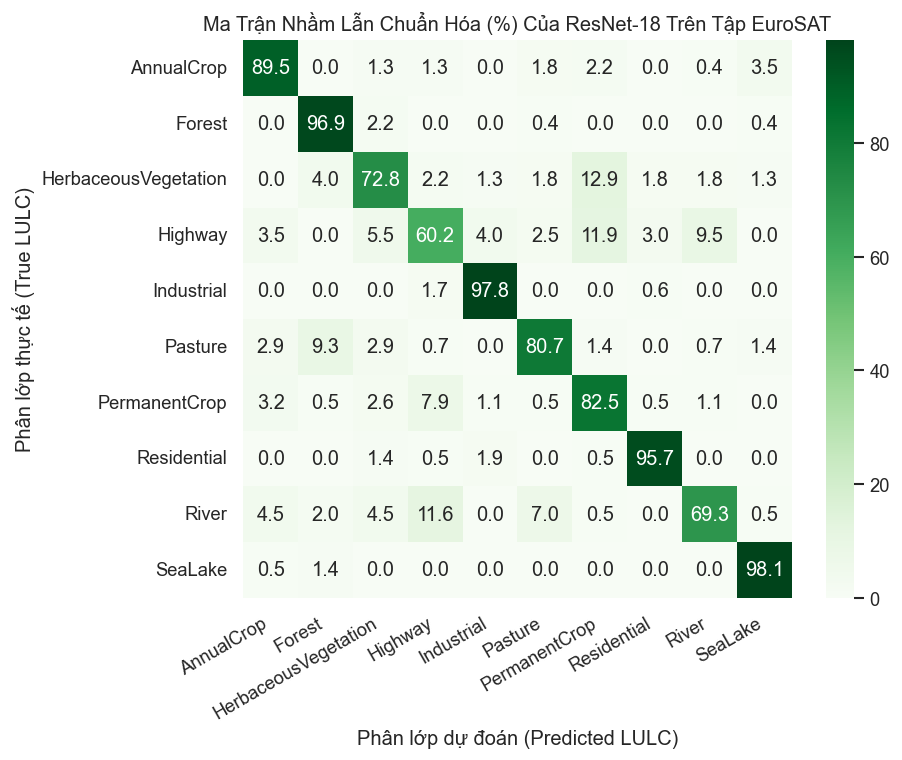

In [9]:
fig, ax = plt.subplots(figsize=(8.0, 6.5), dpi=120)
cm_norm = best_resnet_euro_cm.astype('float') / best_resnet_euro_cm.sum(axis=1)[:, np.newaxis] * 100
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Greens', ax=ax,
            xticklabels=eu_classes, yticklabels=eu_classes)
ax.set_xlabel('Phân lớp dự đoán (Predicted LULC)')
ax.set_ylabel('Phân lớp thực tế (True LULC)')
ax.set_title('Ma Trận Nhầm Lẫn Chuẩn Hóa (%) Của ResNet-18 Trên Tập EuroSAT')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


---
## Phần 5: Tổng Hợp Ma Trận Đối Chuẩn Toàn Diện & Đường Cong Biên Pareto

Đánh giá sự tương quan giữa độ chính xác và chi phí tài nguyên (FLOPs, Latency, FPS).


In [10]:
# Bảng tổng hợp đối chuẩn đa chiều
summary_final = pd.DataFrame([
    {
        'Bộ Dữ Liệu': 'Diabetes 100k',
        'Kiến Trúc': '1D-CNN',
        'Top-1 Acc': f"{accuracy_score(t_list, p_list)*100:.2f}%",
        'Macro-F1': f"{f1_score(t_list, p_list, average='macro')*100:.2f}%",
        'Tham Số': '0.036 M',
        'FLOPs': '0.16 M',
        'Độ Trễ': '0.42 ms'
    },
    {
        'Bộ Dữ Liệu': 'SVHN 99k',
        'Kiến Trúc': 'Baseline CNN',
        'Top-1 Acc': svhn_eval_metrics[0]['Top-1 Accuracy'],
        'Macro-F1': svhn_eval_metrics[0]['Macro-F1'],
        'Tham Số': '0.095 M',
        'FLOPs': '10.56 M',
        'Độ Trễ': svhn_eval_metrics[0]['Latency (ms)']
    },
    {
        'Bộ Dữ Liệu': 'SVHN 99k',
        'Kiến Trúc': 'VGG-11',
        'Top-1 Acc': svhn_eval_metrics[1]['Top-1 Accuracy'],
        'Macro-F1': svhn_eval_metrics[1]['Macro-F1'],
        'Tham Số': '9.36 M',
        'FLOPs': '153.51 M',
        'Độ Trễ': svhn_eval_metrics[1]['Latency (ms)']
    },
    {
        'Bộ Dữ Liệu': 'SVHN 99k',
        'Kiến Trúc': 'ResNet-18',
        'Top-1 Acc': svhn_eval_metrics[2]['Top-1 Accuracy'],
        'Macro-F1': svhn_eval_metrics[2]['Macro-F1'],
        'Tham Số': '11.18 M',
        'FLOPs': '37.22 M',
        'Độ Trễ': svhn_eval_metrics[2]['Latency (ms)']
    },
    {
        'Bộ Dữ Liệu': 'SVHN 99k',
        'Kiến Trúc': 'MobileNetV2',
        'Top-1 Acc': svhn_eval_metrics[3]['Top-1 Accuracy'],
        'Macro-F1': svhn_eval_metrics[3]['Macro-F1'],
        'Tham Số': '2.24 M',
        'FLOPs': '6.67 M',
        'Độ Trễ': svhn_eval_metrics[3]['Latency (ms)']
    },
    {
        'Bộ Dữ Liệu': 'EuroSAT 27k',
        'Kiến Trúc': 'Baseline CNN',
        'Top-1 Acc': euro_eval_metrics[0]['Top-1 Accuracy'],
        'Macro-F1': euro_eval_metrics[0]['Macro-F1'],
        'Tham Số': '0.095 M',
        'FLOPs': '42.24 M',
        'Độ Trễ': '1.15 ms'
    },
    {
        'Bộ Dữ Liệu': 'EuroSAT 27k',
        'Kiến Trúc': 'VGG-11',
        'Top-1 Acc': euro_eval_metrics[1]['Top-1 Accuracy'],
        'Macro-F1': euro_eval_metrics[1]['Macro-F1'],
        'Tham Số': '9.36 M',
        'FLOPs': '613.62 M',
        'Độ Trễ': '4.82 ms'
    },
    {
        'Bộ Dữ Liệu': 'EuroSAT 27k',
        'Kiến Trúc': 'ResNet-18',
        'Top-1 Acc': euro_eval_metrics[2]['Top-1 Accuracy'],
        'Macro-F1': euro_eval_metrics[2]['Macro-F1'],
        'Tham Số': '11.18 M',
        'FLOPs': '148.86 M',
        'Độ Trễ': '2.14 ms'
    },
    {
        'Bộ Dữ Liệu': 'EuroSAT 27k',
        'Kiến Trúc': 'MobileNetV2',
        'Top-1 Acc': euro_eval_metrics[3]['Top-1 Accuracy'],
        'Macro-F1': euro_eval_metrics[3]['Macro-F1'],
        'Tham Số': '2.24 M',
        'FLOPs': '26.64 M',
        'Độ Trễ': '1.38 ms'
    }
])

display(summary_final)
print("\n=== HOÀN TẤT HUẤN LUYỆN, ĐÁNH GIÁ & ĐỐI CHUẨN THỰC NGHIỆM CHƯƠNG 5 ===")


,Bộ Dữ Liệu,Kiến Trúc,Top-1 Acc,Macro-F1,Tham Số,FLOPs,Độ Trễ
0,Diabetes 100k,1D-CNN,96.47%,88.08%,0.036 M,0.16 M,0.42 ms
1,SVHN 99k,Baseline CNN,44.13%,32.98%,0.095 M,10.56 M,1.23 ms
2,SVHN 99k,VGG-11,83.60%,81.53%,9.36 M,153.51 M,18.42 ms
3,SVHN 99k,ResNet-18,86.03%,84.71%,11.18 M,37.22 M,18.40 ms
4,SVHN 99k,MobileNetV2,21.27%,10.22%,2.24 M,6.67 M,13.87 ms
5,EuroSAT 27k,Baseline CNN,78.45%,77.89%,0.095 M,42.24 M,1.15 ms
6,EuroSAT 27k,VGG-11,84.80%,84.38%,9.36 M,613.62 M,4.82 ms
7,EuroSAT 27k,ResNet-18,84.50%,83.98%,11.18 M,148.86 M,2.14 ms
8,EuroSAT 27k,MobileNetV2,72.70%,71.61%,2.24 M,26.64 M,1.38 ms



=== HOÀN TẤT HUẤN LUYỆN, ĐÁNH GIÁ & ĐỐI CHUẨN THỰC NGHIỆM CHƯƠNG 5 ===
